# check

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1.2)
font_path = '..//Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
print("Current font settings:", plt.rcParams['font.sans-serif'])

Current font settings: ['Helvetica']


In [7]:
from scipy.stats import spearmanr
import numpy as np

def mantel_test(sim_df, n_permutations=9999):
    data = sim_df.iloc[:, 2:]
    cl_score = {}

    # Calculate observed Spearman correlation
    for col in ['A549_simu_WTCS', 'PC3_simu_WTCS', 'A375_simu_WTCS', 'HT29_simu_WTCS', 'MCF7_simu_WTCS']:
        flattened_matrix1, flattened_matrix2 = data['UniPert_CS'].values, data[col].values
        observed_corr, _ = spearmanr(flattened_matrix1, flattened_matrix2)
    
        # Initialize list to store permuted correlation values
        permuted_corr = []
        
        # Perform permutation test
        for _ in range(n_permutations):
            # Randomly shuffle the second vector (flattened_matrix2)
            np.random.shuffle(flattened_matrix2)
            
            # Calculate the permuted Spearman correlation
            permuted_corr_value, _ = spearmanr(flattened_matrix1, flattened_matrix2)
            permuted_corr.append(permuted_corr_value)
        
        # Convert list to a numpy array for easier calculation
        permuted_corr = np.array(permuted_corr)
        
        # Calculate p-value (proportion of permuted correlations greater than or equal to observed correlation)
        p_value = np.sum(permuted_corr >= observed_corr) / n_permutations

        print(col, observed_corr, f'p-value: {p_value:.4f}')
        cl_score[col] = (observed_corr, p_value)
    
    return cl_score

In [ ]:
def cal_ranks_chem_chem(file, target, sim_type='UniPert_CS'):
    base_col = ['perturbagen1', 'perturbagen2', 'A549_simu_WTCS', 'PC3_simu_WTCS', 'A375_simu_WTCS', 'HT29_simu_WTCS', 'MCF7_simu_WTCS', sim_type]
    sim_df = pd.read_csv(file).loc[:, base_col]
    sim_df[sim_type] = sim_df[sim_type].fillna(0)
    
    ptbgs = list(set(list(sim_df['perturbagen1'])))
    # print(len(ptbgs))
    
    targets = []
    cps = []
    for i in ptbgs:
        if i[:3] == 'BRD': 
            cps.append(i)
        else:
            targets.append(i)

    sim_df = sim_df[~((sim_df['perturbagen1'].isin(targets)) | (sim_df['perturbagen2'].isin(targets)))]
    data = sim_df.iloc[:, 2:]
    
    spearman_corr = data.corr(method='spearman')
    rank_cl = spearman_corr[sim_type].to_dict()

    # print(targets, len(cps))
    # print(cps)
    return rank_cl, cps, targets, spearman_corr

In [5]:
def filter_sim(sim_df):
    ptbgs = list(set(list(sim_df['perturbagen1'])))
    targets = []
    cps = []
    for i in ptbgs:
        if i[:3] == 'BRD': 
            cps.append(i)
        else:
            targets.append(i)

    cc_cause_sim = sim_df[~((sim_df['perturbagen1'].isin(targets)) | (sim_df['perturbagen2'].isin(targets)))]
    return cc_cause_sim

In [4]:
def plot_cause_heatmap(pcl, sim_df, pert_order=None, color="#8CA0CB", sim_type='UniPert_CS'):
    from scipy.cluster.hierarchy import linkage, leaves_list
    no_pparg_matrix = sim_df.pivot_table(index='perturbagen1', columns='perturbagen2', values='UniPert_CS')
    if pert_order is None:
        linkage = linkage(no_pparg_matrix, method='single', metric='cosine')
        order = leaves_list(linkage)
        pert_order = list(no_pparg_matrix.index[order])
        vmin = -0.2
    else:
        vmin = 0
    cause_ordered_matrix = no_pparg_matrix.loc[pert_order, pert_order]

    custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["w", color])
    fig, ax = plt.subplots(1, 1, figsize=(2, 2))

    for i, cl in enumerate(sim_df.columns[[2]]):
        sns.heatmap(cause_ordered_matrix, cmap=custom_cmap, annot=False, fmt=".2f", 
                    ax=ax, vmin=vmin, vmax=1, cbar=False)

        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel('')
        ax.set_ylabel('')

    plt.show()
    return pert_order


In [3]:
def plot_effect_heatmaps(pcl, sim_df, pert_order):
    custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["w", "#E9685E"])
    data = sim_df.iloc[:, 2:]
    spearman_corr = data.corr(method='spearman')
    rank_cl = spearman_corr.sort_values(by=['UniPert_CS'], ascending=False).index[1:].tolist()

    fig, axes = plt.subplots(5, 1, figsize=(1.05, 6))
    no_pparg_rows = sim_df
    for i, cl in enumerate(sim_df[rank_cl]):
        no_pparg_rows.pivot_table(index='perturbagen1', columns='perturbagen2', values=cl)
        no_pparg_matrix = no_pparg_rows.pivot_table(index='perturbagen1', columns='perturbagen2', values=cl)
        ordered_matrix = no_pparg_matrix.loc[pert_order, pert_order]

        sns.heatmap(ordered_matrix, cmap=custom_cmap, annot=False, fmt=".2f", 
                    ax=axes[i], vmin=0.85, vmax=1, cbar=False)

        axes[i].set_xticklabels([])
        axes[i].set_yticklabels([])
        axes[i].set_xticks([])
        axes[i].set_yticks([])
        axes[i].set_xlabel('')
        axes[i].set_ylabel(cl.split('_')[0], fontsize=18, labelpad=1)

    plt.show() 
    return pd.DataFrame(spearman_corr.sort_values(by=['UniPert_CS'], ascending=True).iloc[:-1, 0])

In [2]:
def plot_spearman_bar_dual(pcl, data, col1='UniPert_CS', col2='ECFP4_Tanimoto', color1='#B7C4DD', color2='#E0E0E0'):
    """
    data: DataFrame, index = perturbagens, columns contain col1 and col2
    """
    data = data.sort_values(by=col1, ascending=True)

    x1 = data[col1].values
    x2 = data[col2].values
    labels = data.index.values
    print(labels)

    y = np.arange(len(data))
    h = 0.42 

    plt.figure(figsize=(1.5, 3.9))
    ax = plt.gca()

    ax.barh(y + h/2, x1, height=h, color=color1, label=col1)
    ax.barh(y - h/2, x2, height=h, color=color2, label=col2)

    for idx, (v1, v2) in enumerate(zip(x1, x2)):
        ax.text(v1 + 0.02, y[idx] + h/2, f"{v1:.2f}", va='center', fontsize=12, color="#4A4A4A")
        ax.text(v2 + 0.02, y[idx] - h/2, f"{v2:.2f}", va='center', fontsize=12, color="#4A4A4A")

    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.set_yticks([])
    ax.set_xticks([])

    plt.tight_layout()
    plt.show()

Glucocorticoid receptor agonist 44 44
['A549_simu_WTCS', 'MCF7_simu_WTCS', 'HT29_simu_WTCS', 'PC3_simu_WTCS', 'A375_simu_WTCS']
['MCF7_simu_WTCS', 'A375_simu_WTCS', 'A549_simu_WTCS', 'HT29_simu_WTCS', 'PC3_simu_WTCS']


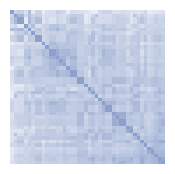

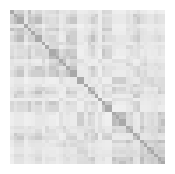

halometasone	
beclometasone	
betamethasone	
dexamethasone	
clocortolone-pivalate	
flumetasone	
desoximetasone	
betamethasone-acetate	
dexamethasone-acetate	
halcinonide	
fluorometholone	
fluocinolone-acetonide	
fluocinonide	
fluocinolone	
fludroxycortide	
flunisolide	
amcinonide	
triamcinolone-acetonide	
triamcinolone	
westcort	
hydrocortisone-valerate	
alclometasone	
fludrocortisone-acetate	
isoflupredone-acetate	
mometasone	
medrysone	
diflorasone	
fluticasone	
fluticasone-propionate	
hydrocortisone-acetate	
hydrocortisone-phosphate	
hydrocortisone-hemisuccinate	
hydrocortisone	
methylprednisolone	
depomedrol	
beclomethasone-dipropionate	
clobetasol	
prednisolone	
budesonide	
loteprednol	
prednicarbate	
rimexolone	
prednisolone-acetate	
prednisolone-hemisuccinate	


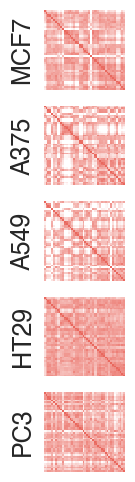

A549_simu_WTCS 0.2723482227383332 p-value: 0.0000
PC3_simu_WTCS 0.2087196126792135 p-value: 0.0000
A375_simu_WTCS 0.3183940903094062 p-value: 0.0000
HT29_simu_WTCS 0.26726156087238256 p-value: 0.0000
MCF7_simu_WTCS 0.3530047826324502 p-value: 0.0000


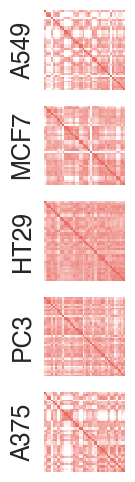

A549_simu_WTCS 0.39244477639598296 p-value: 0.0000
PC3_simu_WTCS 0.3208036730775151 p-value: 0.0000
A375_simu_WTCS 0.2735183259229787 p-value: 0.0000
HT29_simu_WTCS 0.3573629820083414 p-value: 0.0000
MCF7_simu_WTCS 0.3612331828422867 p-value: 0.0000
['A375_simu_WTCS' 'PC3_simu_WTCS' 'HT29_simu_WTCS' 'MCF7_simu_WTCS'
 'A549_simu_WTCS']


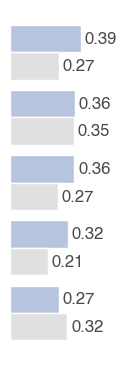

Tubulin inhibitor 20 20
['HT29_simu_WTCS', 'MCF7_simu_WTCS', 'A375_simu_WTCS', 'A549_simu_WTCS', 'PC3_simu_WTCS']
['PC3_simu_WTCS', 'A549_simu_WTCS', 'HT29_simu_WTCS', 'A375_simu_WTCS', 'MCF7_simu_WTCS']


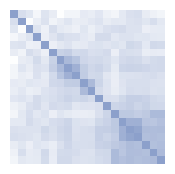

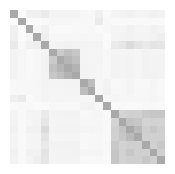

IC-261	
chelidonine	
plinabulin	
ABT-751	
D-64131	
vinorelbine	
vindesine	
vinblastine	
vincristine	
paclitaxel	
docetaxel	
podophyllotoxin	
epothilone	
albendazole	
nocodazole	
mebendazole	
flubendazole	
parbendazole	
fenbendazole	
oxibendazole	


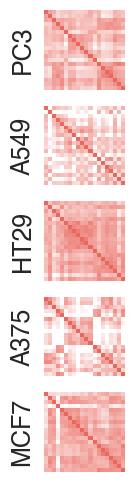

A549_simu_WTCS 0.37516999335953916 p-value: 0.0000
PC3_simu_WTCS 0.5813943445723377 p-value: 0.0000
A375_simu_WTCS 0.31588704460955436 p-value: 0.0000
HT29_simu_WTCS 0.32937225239431916 p-value: 0.0000
MCF7_simu_WTCS 0.3028093709133622 p-value: 0.0000


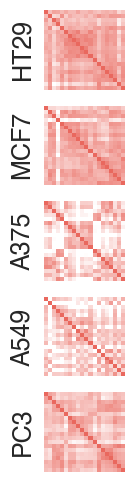

A549_simu_WTCS 0.3829838060714194 p-value: 0.0000
PC3_simu_WTCS 0.3484270360840332 p-value: 0.0000
A375_simu_WTCS 0.39974832084497414 p-value: 0.0000
HT29_simu_WTCS 0.643241500943674 p-value: 0.0000
MCF7_simu_WTCS 0.41875944338247073 p-value: 0.0000
['PC3_simu_WTCS' 'A549_simu_WTCS' 'A375_simu_WTCS' 'MCF7_simu_WTCS'
 'HT29_simu_WTCS']


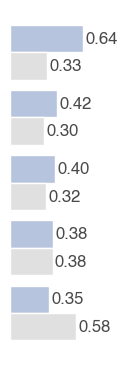

Estrogen receptor agonist 17 17
['MCF7_simu_WTCS', 'HT29_simu_WTCS', 'A375_simu_WTCS', 'PC3_simu_WTCS', 'A549_simu_WTCS']
['MCF7_simu_WTCS', 'HT29_simu_WTCS', 'A375_simu_WTCS', 'A549_simu_WTCS', 'PC3_simu_WTCS']


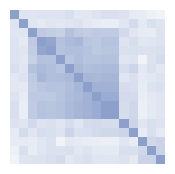

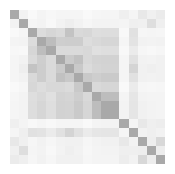

diarylpropionitrile	
coumestrol	
estropipate	
ethinyl-estradiol	
mestranol	
estriol	
estrone	
estradiol	
estradiol-benzoate	
estradiol-cypionate	
estradiol-valerate	
17-beta-estradiol	
PPT	
equilin	
diethylstilbestrol	
daidzein	
dienestrol	


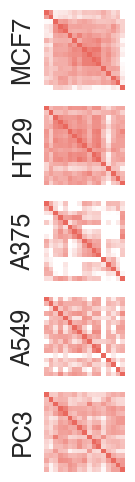

A549_simu_WTCS 0.4703163429374685 p-value: 0.0000
PC3_simu_WTCS 0.4275189259377036 p-value: 0.0000
A375_simu_WTCS 0.47249245572900866 p-value: 0.0000
HT29_simu_WTCS 0.4907381392681628 p-value: 0.0000
MCF7_simu_WTCS 0.6495920403905383 p-value: 0.0000


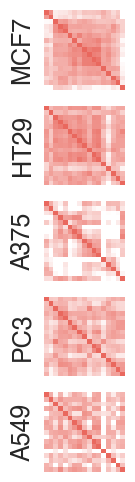

A549_simu_WTCS 0.3749983843125903 p-value: 0.0000
PC3_simu_WTCS 0.40503860666750346 p-value: 0.0000
A375_simu_WTCS 0.4811773705666081 p-value: 0.0000
HT29_simu_WTCS 0.5749958483698122 p-value: 0.0000
MCF7_simu_WTCS 0.7273290567755543 p-value: 0.0000
['A549_simu_WTCS' 'PC3_simu_WTCS' 'A375_simu_WTCS' 'HT29_simu_WTCS'
 'MCF7_simu_WTCS']


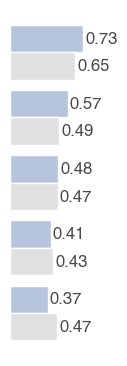

ATPase inhibitor 16 16
['MCF7_simu_WTCS', 'HT29_simu_WTCS', 'PC3_simu_WTCS', 'A375_simu_WTCS', 'A549_simu_WTCS']
['MCF7_simu_WTCS', 'HT29_simu_WTCS', 'PC3_simu_WTCS', 'A549_simu_WTCS', 'A375_simu_WTCS']


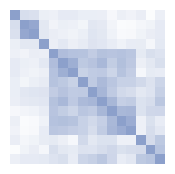

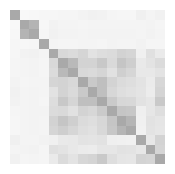

cyclopiazonic-acid	
oligomycin-c	
oligomycin-a	
thapsigargin	
ouabain	
digitoxin	
digoxin	
sarmentogenin	
gitoxigenin	
digitoxigenin	
strophanthidin	
helveticoside	
cymarin	
cinobufagin	
proscillaridin	
bufalin	


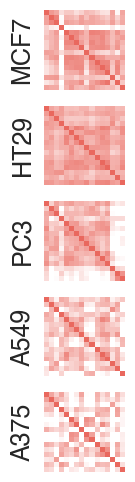

A549_simu_WTCS 0.28815682086336314 p-value: 0.0000
PC3_simu_WTCS 0.39037398650852423 p-value: 0.0000
A375_simu_WTCS 0.21175319684005142 p-value: 0.0001
HT29_simu_WTCS 0.5458187872984636 p-value: 0.0000
MCF7_simu_WTCS 0.6738477110432635 p-value: 0.0000


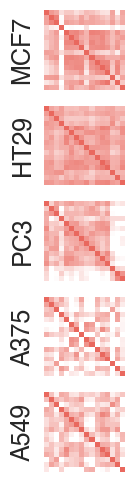

A549_simu_WTCS 0.27353206273980324 p-value: 0.0000
PC3_simu_WTCS 0.46091094128861904 p-value: 0.0000
A375_simu_WTCS 0.286932884754259 p-value: 0.0000
HT29_simu_WTCS 0.5481600832642959 p-value: 0.0000
MCF7_simu_WTCS 0.6413898833224752 p-value: 0.0000
['A549_simu_WTCS' 'A375_simu_WTCS' 'PC3_simu_WTCS' 'HT29_simu_WTCS'
 'MCF7_simu_WTCS']


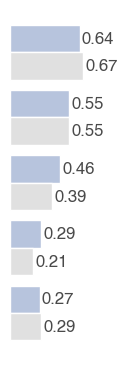

MTOR inhibitor 16 16
['PC3_simu_WTCS', 'HT29_simu_WTCS', 'A375_simu_WTCS', 'MCF7_simu_WTCS', 'A549_simu_WTCS']
['PC3_simu_WTCS', 'MCF7_simu_WTCS', 'A375_simu_WTCS', 'HT29_simu_WTCS', 'A549_simu_WTCS']


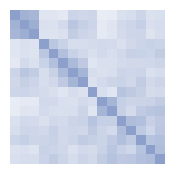

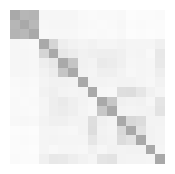

sirolimus	
temsirolimus	
deforolimus	
WYE-125132	
WYE-354	
KU-0063794	
AZD-8055	
OSI-027	
QL-X-138	
NU-7026	
LY-294002	
torin-1	
torin-2	
NVP-BEZ235	
GSK-1059615	
PI-103	


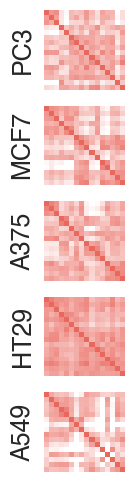

A549_simu_WTCS 0.08107601546643797 p-value: 0.0940
PC3_simu_WTCS 0.4967368044137656 p-value: 0.0000
A375_simu_WTCS 0.3348520331978626 p-value: 0.0000
HT29_simu_WTCS 0.25429044009676804 p-value: 0.0000
MCF7_simu_WTCS 0.33502534573188286 p-value: 0.0000


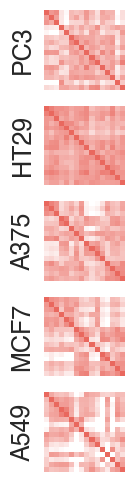

A549_simu_WTCS 0.24174397026877972 p-value: 0.0001
PC3_simu_WTCS 0.5382089863497899 p-value: 0.0000
A375_simu_WTCS 0.4975826638306429 p-value: 0.0000
HT29_simu_WTCS 0.5232018948129643 p-value: 0.0000
MCF7_simu_WTCS 0.3076424689996832 p-value: 0.0000
['A549_simu_WTCS' 'MCF7_simu_WTCS' 'A375_simu_WTCS' 'HT29_simu_WTCS'
 'PC3_simu_WTCS']


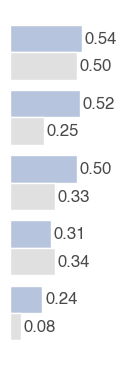

PPAR receptor agonist 16 16
['PC3_simu_WTCS', 'HT29_simu_WTCS', 'MCF7_simu_WTCS', 'A549_simu_WTCS', 'A375_simu_WTCS']
['MCF7_simu_WTCS', 'HT29_simu_WTCS', 'A549_simu_WTCS', 'PC3_simu_WTCS', 'A375_simu_WTCS']


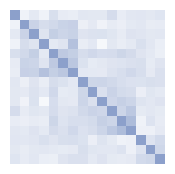

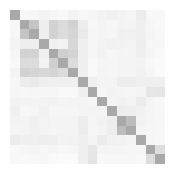

nTZDpa	
pioglitazone	
CAY-10415	
GW-1929	
ciglitazone	
troglitazone	
rosiglitazone	
L-165041	
doconexent	
GW-7647	
pirinixic-acid	
GW-501516	
GW-0742	
bezafibrate	
15-delta-prostaglandin-j2	
HO-013	


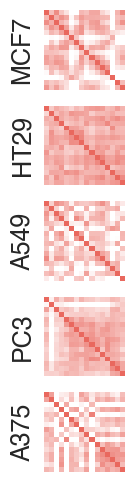

A549_simu_WTCS 0.19201563323387227 p-value: 0.0009
PC3_simu_WTCS 0.11591746801871448 p-value: 0.0321
A375_simu_WTCS 0.059077765055674095 p-value: 0.1705
HT29_simu_WTCS 0.332817280514121 p-value: 0.0000
MCF7_simu_WTCS 0.33631693933487455 p-value: 0.0000


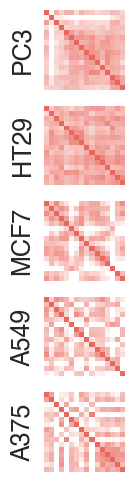

A549_simu_WTCS 0.1544459267667137 p-value: 0.0067
PC3_simu_WTCS 0.4025785630548434 p-value: 0.0000
A375_simu_WTCS 0.10068937002564816 p-value: 0.0521
HT29_simu_WTCS 0.30586808880925775 p-value: 0.0000
MCF7_simu_WTCS 0.2641069179861691 p-value: 0.0001
['A375_simu_WTCS' 'A549_simu_WTCS' 'MCF7_simu_WTCS' 'HT29_simu_WTCS'
 'PC3_simu_WTCS']


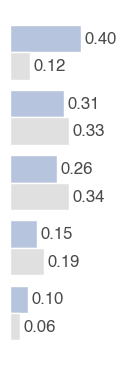

Topoisomerase inhibitor 15 16
['A549_simu_WTCS', 'A375_simu_WTCS', 'HT29_simu_WTCS', 'MCF7_simu_WTCS', 'PC3_simu_WTCS']
['HT29_simu_WTCS', 'A375_simu_WTCS', 'A549_simu_WTCS', 'PC3_simu_WTCS', 'MCF7_simu_WTCS']


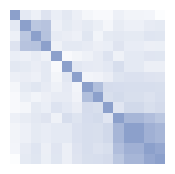

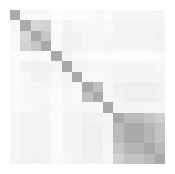

celastrol	
irinotecan	
camptothecin	
topotecan	
ellipticine	
amsacrine	
amonafide	
teniposide	
etoposide	
mitoxantrone	
pirarubicin	
epirubicin	
doxorubicin	
daunorubicin	
idarubicin	


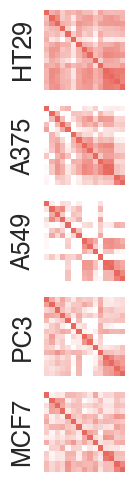

A549_simu_WTCS 0.44795676202794893 p-value: 0.0000
PC3_simu_WTCS 0.32249443652841703 p-value: 0.0000
A375_simu_WTCS 0.5014604272300814 p-value: 0.0000
HT29_simu_WTCS 0.6196814123908438 p-value: 0.0000
MCF7_simu_WTCS 0.2948600205248446 p-value: 0.0000


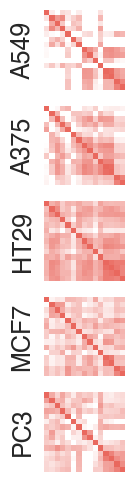

A549_simu_WTCS 0.5793846691026848 p-value: 0.0000
PC3_simu_WTCS 0.3633418069034205 p-value: 0.0000
A375_simu_WTCS 0.5348598541970215 p-value: 0.0000
HT29_simu_WTCS 0.5019154379300265 p-value: 0.0000
MCF7_simu_WTCS 0.4619092767385429 p-value: 0.0000
['PC3_simu_WTCS' 'MCF7_simu_WTCS' 'HT29_simu_WTCS' 'A375_simu_WTCS'
 'A549_simu_WTCS']


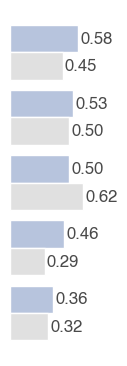

Aurora kinase inhibitor 14 14
['MCF7_simu_WTCS', 'PC3_simu_WTCS', 'A549_simu_WTCS', 'HT29_simu_WTCS', 'A375_simu_WTCS']
['MCF7_simu_WTCS', 'A549_simu_WTCS', 'HT29_simu_WTCS', 'PC3_simu_WTCS', 'A375_simu_WTCS']


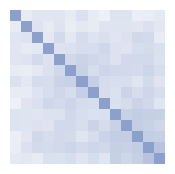

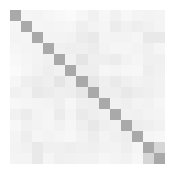

OM-137	
MK-5108	
danusertib	
AT-9283	
JWE-035	
reversine	
aurora-a-inhibitor-i	
ZM-447439	
GSK-1070916	
alisertib	
barasertib-HQPA	
SNS-314	
tozasertib	
ENMD-2076	


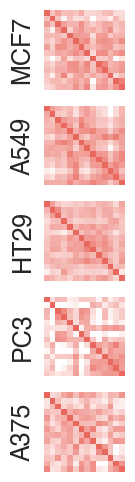

A549_simu_WTCS 0.3226066257095377 p-value: 0.0000
PC3_simu_WTCS 0.2608814931472438 p-value: 0.0001
A375_simu_WTCS 0.15962763868598903 p-value: 0.0113
HT29_simu_WTCS 0.31138454442293045 p-value: 0.0000
MCF7_simu_WTCS 0.423247090238621 p-value: 0.0000


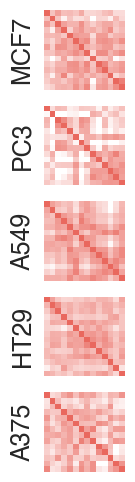

A549_simu_WTCS 0.4870564312561245 p-value: 0.0000
PC3_simu_WTCS 0.5429478167559663 p-value: 0.0000
A375_simu_WTCS 0.23944246239685046 p-value: 0.0003
HT29_simu_WTCS 0.3745738539936015 p-value: 0.0000
MCF7_simu_WTCS 0.5489831587763689 p-value: 0.0000
['A375_simu_WTCS' 'HT29_simu_WTCS' 'A549_simu_WTCS' 'PC3_simu_WTCS'
 'MCF7_simu_WTCS']


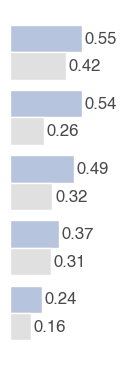

CDK inhibitor 12 12
['HT29_simu_WTCS', 'PC3_simu_WTCS', 'MCF7_simu_WTCS', 'A549_simu_WTCS', 'A375_simu_WTCS']
['A375_simu_WTCS', 'HT29_simu_WTCS', 'MCF7_simu_WTCS', 'A549_simu_WTCS', 'PC3_simu_WTCS']


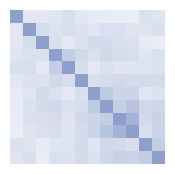

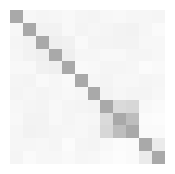

Ro-3306	
JNJ-7706621	
palbociclib	
AT-7519	
PHA-793887	
NSC-693868	
aloisine	
roscovitine	
aminopurvalanol-a	
purvalanol-a	
indirubin-3-monoxime	
kenpaullone	


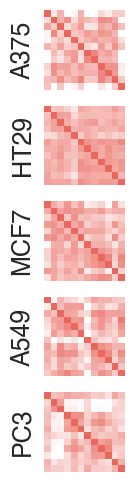

A549_simu_WTCS 0.2774805805989524 p-value: 0.0004
PC3_simu_WTCS 0.24341459181304462 p-value: 0.0027
A375_simu_WTCS 0.4174183867178809 p-value: 0.0000
HT29_simu_WTCS 0.3791486932759444 p-value: 0.0000
MCF7_simu_WTCS 0.34438371843973165 p-value: 0.0000


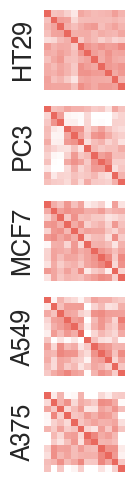

A549_simu_WTCS 0.3593060848698724 p-value: 0.0000
PC3_simu_WTCS 0.4382504322807173 p-value: 0.0000
A375_simu_WTCS 0.30322213026137834 p-value: 0.0001
HT29_simu_WTCS 0.6015622723877058 p-value: 0.0000
MCF7_simu_WTCS 0.4317551018868239 p-value: 0.0000
['A375_simu_WTCS' 'A549_simu_WTCS' 'MCF7_simu_WTCS' 'PC3_simu_WTCS'
 'HT29_simu_WTCS']


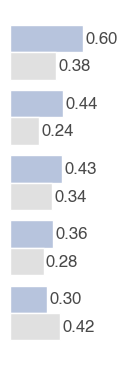

Beta-adrenergic receptor agonist 11 11
['A549_simu_WTCS', 'A375_simu_WTCS', 'PC3_simu_WTCS', 'HT29_simu_WTCS', 'MCF7_simu_WTCS']
['A549_simu_WTCS', 'HT29_simu_WTCS', 'A375_simu_WTCS', 'PC3_simu_WTCS', 'MCF7_simu_WTCS']


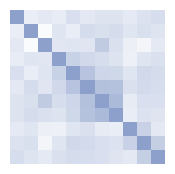

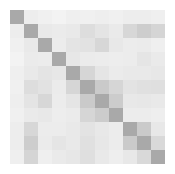

procaterol	
ritodrine	
cimaterol	
salmeterol	
formoterol	
fenoterol	
orciprenaline	
terbutaline-hemisulfate	
isoxsuprine	
buphenine	
dobutamine	


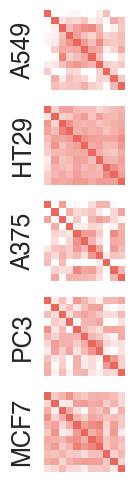

A549_simu_WTCS 0.6210157611729998 p-value: 0.0000
PC3_simu_WTCS 0.31012858895947487 p-value: 0.0005
A375_simu_WTCS 0.43703824362199023 p-value: 0.0000
HT29_simu_WTCS 0.45738138725398764 p-value: 0.0000
MCF7_simu_WTCS 0.25709737157109214 p-value: 0.0027


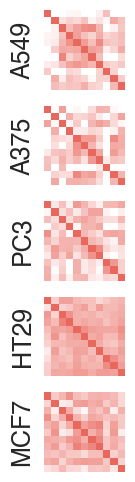

A549_simu_WTCS 0.6207729550472184 p-value: 0.0000
PC3_simu_WTCS 0.5304576441905454 p-value: 0.0000
A375_simu_WTCS 0.5638419878410758 p-value: 0.0000
HT29_simu_WTCS 0.5106295762947156 p-value: 0.0000
MCF7_simu_WTCS 0.4938723326201858 p-value: 0.0000
['MCF7_simu_WTCS' 'HT29_simu_WTCS' 'PC3_simu_WTCS' 'A375_simu_WTCS'
 'A549_simu_WTCS']


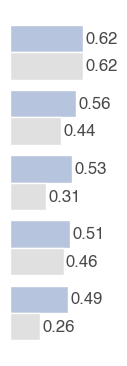

In [ ]:
import os
import pandas as pd

cl_rank_res = {}
cl_rank_res_ecfp = {}
raw_res = pd.read_csv('../G2CP/data/CMAP_mmc1.txt', sep='\t').sort_values(by='Size', ascending=False)

for index, row in raw_res.iterrows():
    s = row['Size']
    pcl = row['PCL Name']
    tau_sum = row['Tau Summary']
    perturbagen_ids = row['Perturbagen IDs']
    perturbagens = row['Pertubagen Names']
    gene_targets = row['Gene Targets']
    best_cl = row['Best Cell']

    cps = perturbagen_ids.split('|')
    cps_name = perturbagens.split('|')
    mapping_dict = dict(zip(cps, cps_name))
    for q in gene_targets.split('|'):
        file_path = f'../G2CP/results/PCL_cause_effect_connectivity/{pcl}_pairwise_sim.csv'
        if os.path.exists(file_path):
            raw_sim_df = pd.read_csv(file_path)
            if 'ECFP4_Tanimoto' not in raw_sim_df.columns: continue

            raw_sim_df = filter_sim(raw_sim_df)
            sim_df_unipert = raw_sim_df.copy().drop(columns=['ECFP4_Tanimoto'])
            sim_df_ecfp = raw_sim_df.copy()
            sim_df_ecfp['UniPert_CS'] = sim_df_ecfp['ECFP4_Tanimoto'].fillna(0)
            sim_df_ecfp = sim_df_ecfp.drop(columns=['ECFP4_Tanimoto'])
            
            rank_cl, cps, target, spearman_corr = cal_ranks_chem_chem(file_path, gene_targets, 'UniPert_CS')
            cl_order = list(spearman_corr.sort_values(by=['UniPert_CS'], ascending=False).iloc[1:, 0].index)

            rank_cl_ecfp, cps, target, spearman_corr_ecfp = cal_ranks_chem_chem(file_path, gene_targets, 'ECFP4_Tanimoto')
            cl_order_ecfp = list(spearman_corr_ecfp.sort_values(by=['ECFP4_Tanimoto'], ascending=False).iloc[1:, 0].index)

            # filter PCLs by minimum member number
            if len(cps)>10:
                print(pcl, len(cps), s)
                print(cl_order)
                print(cl_order_ecfp)
                # ---- CS_cause heatmap ----
                pert_order_unipert = plot_cause_heatmap(pcl, sim_df_unipert, color="#8CA0CB", sim_type='UniPert_CS')
                pert_order_ecfp = plot_cause_heatmap(pcl, sim_df_ecfp, pert_order_unipert, color="#A9A9A9", sim_type='ECFP4_Tanimoto')
                for cp in pert_order_unipert:
                    print(mapping_dict[cp]+'\t')

                # ---- CS_effect heatmap ----    
                cl_score_ecfp = plot_effect_heatmaps(pcl, sim_df_ecfp, pert_order_unipert)
                mantel_test(sim_df_ecfp)
                cl_score_unipert = plot_effect_heatmaps(pcl, sim_df_unipert, pert_order_unipert)
                mantel_test(sim_df_unipert)
                
                cl_score_ecfp.rename(columns={'UniPert_CS': 'ECFP4_Tanimoto'}, inplace=True)
                cl_score_dual = pd.merge(cl_score_unipert, cl_score_ecfp, left_index=True, right_index=True)

                # ---- CS_cause vs CS_effect barplot ----
                plot_spearman_bar_dual(pcl, cl_score_dual, 'UniPert_CS', 'ECFP4_Tanimoto')
                cl_rank_res[pcl+'_'+f'{q}'+f'_{len(cps)}_{best_cl}'] = rank_cl
                cl_rank_res_ecfp[pcl+'_'+f'{q}'+f'_{len(cps)}_{best_cl}'] = rank_cl_ecfp
                break

In [18]:
cl_rank_res

{'Glucocorticoid receptor agonist_NR3C1_44_A549': {'A549_simu_WTCS': 0.39244477639598296,
  'PC3_simu_WTCS': 0.32080367307751506,
  'A375_simu_WTCS': 0.27351832592297876,
  'HT29_simu_WTCS': 0.35736298200834143,
  'MCF7_simu_WTCS': 0.3612331828422868,
  'UniPert_CS': 1.0},
 'Tubulin inhibitor_TUBB_20_HT29': {'A549_simu_WTCS': 0.3829838060714194,
  'PC3_simu_WTCS': 0.3484270360840332,
  'A375_simu_WTCS': 0.3997483208449742,
  'HT29_simu_WTCS': 0.643241500943674,
  'MCF7_simu_WTCS': 0.41875944338247073,
  'UniPert_CS': 1.0},
 'Estrogen receptor agonist_ESR1_17_MCF7': {'A549_simu_WTCS': 0.37499838431259025,
  'PC3_simu_WTCS': 0.40503860666750346,
  'A375_simu_WTCS': 0.48117737056660803,
  'HT29_simu_WTCS': 0.5749958483698122,
  'MCF7_simu_WTCS': 0.7273290567755543,
  'UniPert_CS': 1.0},
 'ATPase inhibitor_ATP1A1_16_MCF7': {'A549_simu_WTCS': 0.27353206273980324,
  'PC3_simu_WTCS': 0.4609109412886189,
  'A375_simu_WTCS': 0.28693288475425893,
  'HT29_simu_WTCS': 0.5481600832642959,
  'MCF7_s

In [54]:
res = pd.DataFrame(cl_rank_res).iloc[:-1, :].T
res

,A549_simu_WTCS,PC3_simu_WTCS,A375_simu_WTCS,HT29_simu_WTCS,MCF7_simu_WTCS
Glucocorticoid receptor agonist_NR3C1_44_A549,0.392445,0.320804,0.273518,0.357363,0.361233
Tubulin inhibitor_TUBB_20_HT29,0.382984,0.348427,0.399748,0.643242,0.418759
Estrogen receptor agonist_ESR1_17_MCF7,0.374998,0.405039,0.481177,0.574996,0.727329
ATPase inhibitor_ATP1A1_16_MCF7,0.273532,0.460911,0.286933,0.548160,0.641390
MTOR inhibitor_MTOR_16_PC3,0.241744,0.538209,0.497583,0.523202,0.307642
PPAR receptor agonist_PPARG_16_HT29,0.154446,0.402579,0.100689,0.305868,0.264107
Topoisomerase inhibitor_TOP2A_15_A549,0.579385,0.363342,0.534860,0.501915,0.461909
Aurora kinase inhibitor_AURKA_14_MCF7,0.487056,0.542948,0.239442,0.374574,0.548983
CDK inhibitor_CDK1_12_MCF7,0.359306,0.438250,0.303222,0.601562,0.431755
Beta-adrenergic receptor agonist_ADRB2_11_A375,0.620773,0.530458,0.563842,0.510630,0.493872


In [20]:
res.mean().mean()

0.4299428461254108

[Text(0.5, 0, 'PC3_simu_WTCS'), Text(1.5, 0, 'A549_simu_WTCS'), Text(2.5, 0, 'A375_simu_WTCS'), Text(3.5, 0, 'HT29_simu_WTCS'), Text(4.5, 0, 'MCF7_simu_WTCS')]
[Text(1, 0.5, 'Topoisomerase inhibitor_TOP2A_15_A549'), Text(1, 1.5, 'Beta-adrenergic receptor agonist_ADRB2_11_A375'), Text(1, 2.5, 'Glucocorticoid receptor agonist_NR3C1_44_A549'), Text(1, 3.5, 'Aurora kinase inhibitor_AURKA_14_MCF7'), Text(1, 4.5, 'Estrogen receptor agonist_ESR1_17_MCF7'), Text(1, 5.5, 'ATPase inhibitor_ATP1A1_16_MCF7'), Text(1, 6.5, 'Tubulin inhibitor_TUBB_20_HT29'), Text(1, 7.5, 'CDK inhibitor_CDK1_12_MCF7'), Text(1, 8.5, 'MTOR inhibitor_MTOR_16_PC3'), Text(1, 9.5, 'PPAR receptor agonist_PPARG_16_HT29')]
['PC3', 'A549', 'A375', 'HT29', 'MCF7']
['Topoisomerase inhibitor', 'Beta-adrenergic receptor agonist', 'Glucocorticoid receptor agonist', 'Aurora kinase inhibitor', 'Estrogen receptor agonist', 'ATPase inhibitor', 'Tubulin inhibitor', 'CDK inhibitor', 'MTOR inhibitor', 'PPAR receptor agonist']


/data/liyiming/miniconda3/envs/performer/lib/python3.9/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  self._figure.tight_layout(**tight_params)
/tmp/ipykernel_3569976/2034540960.py:56: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


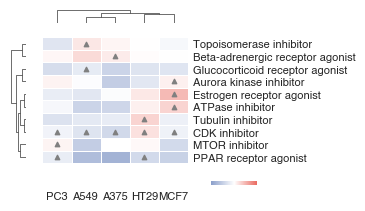

In [65]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

g = sns.clustermap(res, 
                   cmap=mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#8CA0CB", 'w', "#E9685E"]),
                   figsize=(2.3, 2),
                   cbar_pos=(1, 0.0, 0.2, 0.02),  
                   cbar_kws={'label': '', 'orientation': 'horizontal'}, 
                   annot_kws={'size': 0.5},  
                   xticklabels=True,
                   yticklabels=True,  
                   linewidths=0.5,  
                   dendrogram_ratio=(0.1, 0.1),  
                   tree_kws={'linewidths': 0.5},
                   metric="correlation",
                   vmin=0, 
                   vmax=1   
                   )  

colorbar = g.ax_heatmap.collections[0].colorbar
colorbar.ax.set_xticks([]) 

g.tick_params('both', length=0)

xticks = g.ax_heatmap.get_xticklabels().copy()
yticks = g.ax_heatmap.get_yticklabels().copy()
print(xticks)
print(yticks)

new_yticklabels = [label.get_text().split('_')[0] for label in yticks]
new_xticklabels = [label.get_text().split('_')[0] for label in xticks]
print(new_xticklabels)
print(new_yticklabels)

for i, label in enumerate(yticks):
   # additional reported siginificant cell lines from CMAP paper and results
   if 'PPAR' in label.get_text():
      g.ax_heatmap.scatter(new_xticklabels.index('PC3')+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)
      g.ax_heatmap.scatter(new_xticklabels.index('HT29')+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)
   elif 'CDK' in label.get_text():
      g.ax_heatmap.scatter(new_xticklabels.index('PC3')+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)
      g.ax_heatmap.scatter(new_xticklabels.index('A375')+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)
      g.ax_heatmap.scatter(new_xticklabels.index('A549')+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)
      g.ax_heatmap.scatter(new_xticklabels.index('HT29')+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)
      g.ax_heatmap.scatter(new_xticklabels.index('MCF7')+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)
   else:
      best_cl = label.get_text().split('_')[-1]
      g.ax_heatmap.scatter(new_xticklabels.index(best_cl)+0.5, i+0.5, marker='^', color='gray', s=10, zorder=5)

g.ax_heatmap.set_yticklabels(new_yticklabels, fontsize=8)  
g.ax_heatmap.set_xticklabels(new_xticklabels, fontsize=8, rotation=0)  
g.ax_heatmap.tick_params('x', pad=20)


plt.tight_layout()
plt.show()

In [66]:
pd.DataFrame(cl_rank_res_ecfp)

,Glucocorticoid receptor agonist_NR3C1_44_A549,Tubulin inhibitor_TUBB_20_HT29,Estrogen receptor agonist_ESR1_17_MCF7,ATPase inhibitor_ATP1A1_16_MCF7,MTOR inhibitor_MTOR_16_PC3,PPAR receptor agonist_PPARG_16_HT29,Topoisomerase inhibitor_TOP2A_15_A549,Aurora kinase inhibitor_AURKA_14_MCF7,CDK inhibitor_CDK1_12_MCF7,Beta-adrenergic receptor agonist_ADRB2_11_A375
A549_simu_WTCS,0.272348,0.375170,0.470316,0.288157,0.081076,0.192016,0.447957,0.322607,0.277481,0.621016
PC3_simu_WTCS,0.208720,0.581394,0.427519,0.390374,0.496737,0.115917,0.322494,0.260881,0.243415,0.310129
A375_simu_WTCS,0.318394,0.315887,0.472492,0.211753,0.334852,0.059078,0.501460,0.159628,0.417418,0.437038
HT29_simu_WTCS,0.267262,0.329372,0.490738,0.545819,0.254290,0.332817,0.619681,0.311385,0.379149,0.457381
MCF7_simu_WTCS,0.353005,0.302809,0.649592,0.673848,0.335025,0.336317,0.294860,0.423247,0.344384,0.257097
ECFP4_Tanimoto,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [67]:
res_ecfp = pd.DataFrame(cl_rank_res_ecfp).iloc[:-1, :].T
res_ecfp.index = res_ecfp.index.str.split('_').str[0]
res_ecfp.columns = res_ecfp.columns.str.split('_').str[0]
res_ecfp

,A549,PC3,A375,HT29,MCF7
Glucocorticoid receptor agonist,0.272348,0.208720,0.318394,0.267262,0.353005
Tubulin inhibitor,0.375170,0.581394,0.315887,0.329372,0.302809
Estrogen receptor agonist,0.470316,0.427519,0.472492,0.490738,0.649592
ATPase inhibitor,0.288157,0.390374,0.211753,0.545819,0.673848
MTOR inhibitor,0.081076,0.496737,0.334852,0.254290,0.335025
PPAR receptor agonist,0.192016,0.115917,0.059078,0.332817,0.336317
Topoisomerase inhibitor,0.447957,0.322494,0.501460,0.619681,0.294860
Aurora kinase inhibitor,0.322607,0.260881,0.159628,0.311385,0.423247
CDK inhibitor,0.277481,0.243415,0.417418,0.379149,0.344384
Beta-adrenergic receptor agonist,0.621016,0.310129,0.437038,0.457381,0.257097


In [68]:
res_ecfp.mean().mean()

0.35783606362585957

In [71]:
res_ecfp.reindex(index=y_order, columns=x_order)

,PC3,A549,A375,HT29,MCF7
Topoisomerase inhibitor,0.322494,0.447957,0.501460,0.619681,0.294860
Beta-adrenergic receptor agonist,0.310129,0.621016,0.437038,0.457381,0.257097
Glucocorticoid receptor agonist,0.208720,0.272348,0.318394,0.267262,0.353005
Aurora kinase inhibitor,0.260881,0.322607,0.159628,0.311385,0.423247
Estrogen receptor agonist,0.427519,0.470316,0.472492,0.490738,0.649592
ATPase inhibitor,0.390374,0.288157,0.211753,0.545819,0.673848
Tubulin inhibitor,0.581394,0.375170,0.315887,0.329372,0.302809
CDK inhibitor,0.243415,0.277481,0.417418,0.379149,0.344384
MTOR inhibitor,0.496737,0.081076,0.334852,0.254290,0.335025
PPAR receptor agonist,0.115917,0.192016,0.059078,0.332817,0.336317


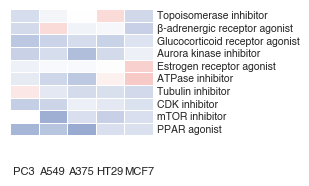

In [74]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

res_plot = res_ecfp.reindex(index=y_order, columns=x_order)

cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#8CA0CB", 'w', "#E9685E"])
fig, ax = plt.subplots(figsize=(3.4, 2.1))

sns.heatmap(
    res_plot,
    cmap=cmap,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    cbar=False,
    cbar_kws={'orientation': 'horizontal', 'fraction':0.08, 'pad':0.2}
)


new_xticklabels = [label.split('_')[0] for label in x_order]
new_yticklabels = \
['Topoisomerase inhibitor',
 'β-adrenergic receptor agonist',
 'Glucocorticoid receptor agonist',
 'Aurora kinase inhibitor',
 'Estrogen receptor agonist',
 'ATPase inhibitor',
 'Tubulin inhibitor',
 'CDK inhibitor',
 'mTOR inhibitor',
 'PPAR agonist']

ax.set_xticks([i+0.5 for i in range(len(x_order))])
ax.set_yticks([i+0.5 for i in range(len(y_order))])

ax.set_xticklabels(new_xticklabels, fontsize=8, rotation=0)
ax.set_yticklabels(new_yticklabels, fontsize=7.5, rotation=0, ha='left', position=(1.06, 0))

ax.tick_params(axis='x', pad=22)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()